# IND320 Part 3: Weather and reservoir patterns

- [Public GitHub repository](https://github.com/Yangocito/ind320-reservoir-dashboard-yangocito)
- [Streamlit dashboard](https://ind320-reservoir-dashboard-yangocito-jqlwog89hlllmliwtrhsmd.streamlit.app/)

Run this notebook from the project folder using Python 3.11 or 3.12. Install `requirements-notebook.txt` first. The analysis functions are shared with Streamlit so the same parameters produce the same results.

## NVE regions and reproducible sampling

The shapefiles under `data/regions` come from the [NVE elspot layer](https://gis3.nve.no/map/rest/services/Mapservices/Omradekonsesjoner/MapServer/8) and the [NVE region layer](https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon2/MapServer/0). The second file contains NVE administrative regions. Its codes match the task, but its boundaries are an approximation of the reservoir catchment areas.

For the API selector, VASS1 (east) uses RS + RØ, VASS2 (west) uses RV, and the northern grouping is split between VASS3 (RM) and VASS4 (RN). Sample 1,000 points within each polygon or group, accounting for holes and drawing uniformly in sine of latitude to approximate equal area.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from analyses import (filling_spectrogram, filling_stl, precipitation_spc,
                      temperature_lof, weekly_filling)
from utils import fetch_reservoirs
from weather import download_weather, grid_weights, sample_locations

# A fixed seed makes the sample repeatable in the notebook and app.
locations = sample_locations(count=1000, seed=320)
sample_counts = pd.DataFrame({
    "Sampled points": {region: len(points) for region, points in locations.items()},
    "Unique ERA5 cells": {region: len(grid_weights(points))
                         for region, points in locations.items()},
})
display(sample_counts)

,Sampled points,Unique ERA5 cells
NO1,1000,184
NO2,1000,150
NO3,1000,235
NO4,1000,451
NO5,1000,99
VASS1,1000,360
VASS2,1000,226
VASS3,1000,277
VASS4,1000,499
NORWAY,1000,724


## Hourly historical weather for NO3 in 2024

[Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) provides ERA5 temperature at 2 m, total precipitation and relative humidity. The task mentions a single location and also a region average. This notebook uses all 1,000 sampled NO3 locations in the regional mean.

The native grid is 0.25°. Select the nearest cell with elevation correction disabled, request each distinct cell once, and weight each response by how many sampled points it represents. Download in batches and cache completed requests locally. Keep the time series in UTC so leap day is included and daylight saving does not introduce missing or duplicated hours.

In [2]:
# 2024 is a leap year, so a complete hourly UTC series contains 8,784 rows.
weather = download_weather("NO3", "2024-01-01", "2024-12-31", locations)
assert len(weather) == 366 * 24 and weather.notna().all().all()
print(weather.attrs)
display(weather.head())

{'region': 'NO3', 'sampled_locations': 1000, 'era5_cells': 235}


,temperature_2m,precipitation,relative_humidity_2m
time_utc,,,
2024-01-01 00:00:00+00:00,-5.6107,0.0045,71.129
2024-01-01 01:00:00+00:00,-5.7730,0.0042,71.124
2024-01-01 02:00:00+00:00,-5.7347,0.0042,70.710
2024-01-01 03:00:00+00:00,-5.7596,0.0042,70.234
2024-01-01 04:00:00+00:00,-5.6801,0.0040,69.904


## Precipitation: DCT and statistical process control

The DCT removes fluctuations with periods of 30 days or longer by default. Estimate the center and scale of the resulting residuals using the median and scaled median absolute deviation across all of 2024. Add the slow component back to the limits so the chart shows the original precipitation and boundaries in millimetres. Red points mark hours outside the limits. Negative lower limits are statistical thresholds.

{'observations': 8784, 'outliers': 375, 'outlier_percent': 4.26912568306011, 'robust_sigma_mm': np.float64(0.16053099487946626)}


,precipitation_mm,lower_limit,upper_limit
time_utc,,,
2024-12-15 18:00:00+00:00,3.3959,-0.395539,0.888709
2024-12-15 19:00:00+00:00,3.0639,-0.395201,0.889047
2024-12-15 17:00:00+00:00,3.0338,-0.395877,0.888371
2024-02-02 18:00:00+00:00,2.6745,-0.380647,0.903601
2024-02-02 17:00:00+00:00,2.4447,-0.380064,0.904184


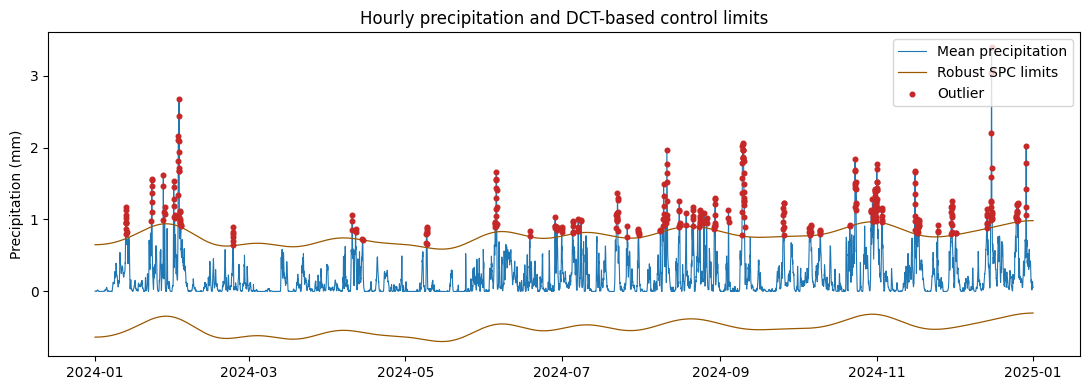

In [3]:
# Try the default 30-day cutoff and four robust deviations.
figure, spc_summary, spc_outliers = precipitation_spc(weather["precipitation"])
print(spc_summary)
display(spc_outliers.sort_values("precipitation_mm", ascending=False).head())
display(figure)
plt.close(figure)

## Temperature: Local Outlier Factor

LOF compares each observation to its local neighbourhood. Standardised temperature and cyclic hour-of-day and day-of-year features give context to unusually warm or cold readings. The default contamination is 1%. A larger LOF score indicates a less typical observation in this feature space.

{'observations': 8784, 'anomalies': 88, 'anomaly_percent': 1.0018214936247722}


,temperature_c,lof_score
time_utc,,
2024-06-28 00:00:00+00:00,18.4544,1.609237
2024-06-27 23:00:00+00:00,18.9248,1.609202
2024-06-28 01:00:00+00:00,18.1726,1.606917
2024-06-28 02:00:00+00:00,17.9328,1.600076
2024-06-28 03:00:00+00:00,18.0614,1.589463


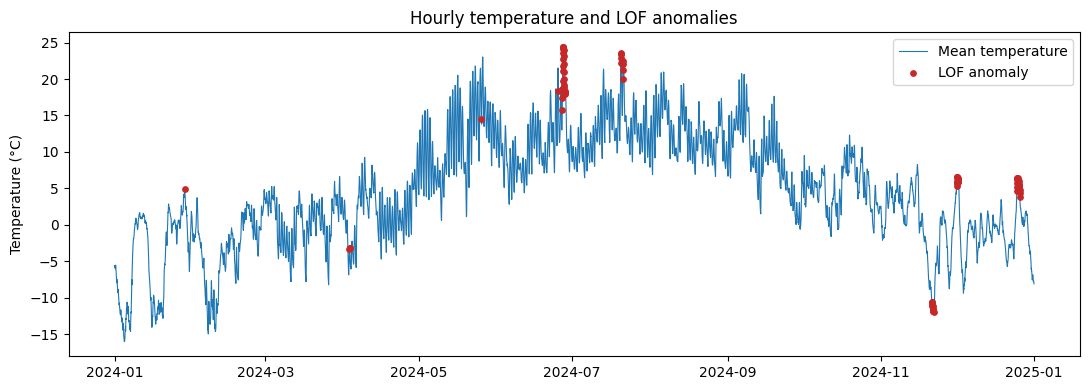

In [4]:
# The contamination argument sets the expected fraction flagged by LOF.
figure, lof_summary, lof_anomalies = temperature_lof(weather["temperature_2m"], proportion=0.01)
print(lof_summary)
display(lof_anomalies.head())
display(figure)
plt.close(figure)

## Reservoir filling: seasonal-trend decomposition

Read [NVE Magasinstatistikk](https://api.nve.no/doc/magasinstatistikk/) directly. Use one NO3 measurement per ISO week, in percent. The STL decomposition uses a 52-week period with adjustable seasonal and trend smoothers and an optional robust fit.

1,661 weeks, 1995-01-02 to 2026-10-26
Interpolated weeks: 0


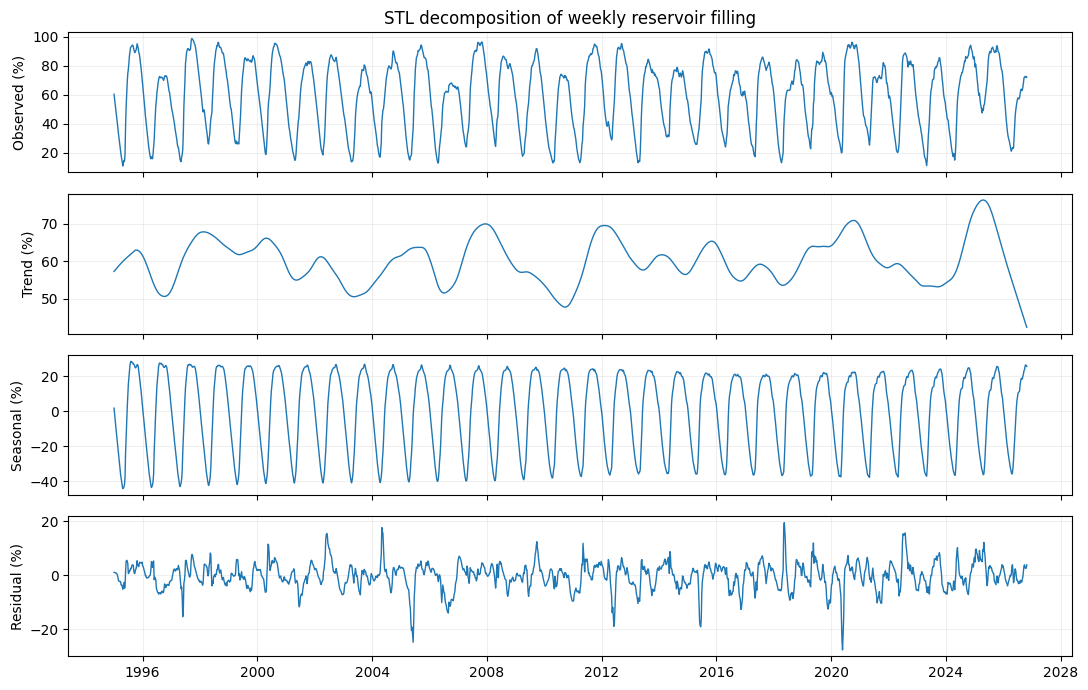

In [5]:
# EL is NVE's API type for price areas. Area 3 is NO3.
reservoirs = fetch_reservoirs()
filling = weekly_filling(reservoirs, "EL", 3)
print(f"{len(filling):,} weeks, {filling.index.min().date()} to {filling.index.max().date()}")
print(f"Interpolated weeks: {filling.attrs['interpolated_weeks']}")
figure = filling_stl(filling, seasonal=13, trend=79, robust=True)
display(figure)
plt.close(figure)

## Reservoir filling: spectrogram

Use the same weekly series, with 156-week Hann windows and 117-week overlap by default. Remove the linear trend within each window. The vertical scale shows cycles per year, so an annual oscillation appears near one cycle per year.

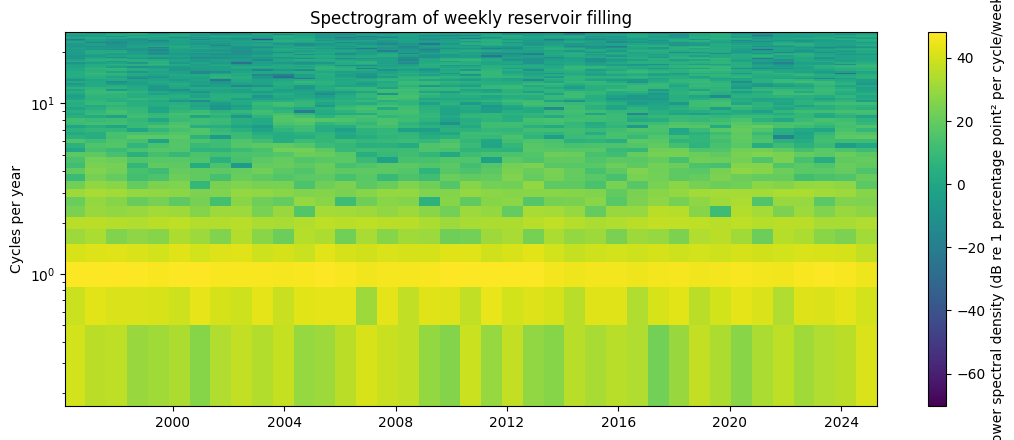

In [6]:
# Window length controls frequency resolution. Overlap controls spacing in time.
figure = filling_spectrogram(filling, window=156, overlap=117)
display(figure)
plt.close(figure)

## Work log

I used the dashboard from Part 2 as the starting point. The app already had pages for reservoir statistics and cross-border electricity flows, so the new work could use the existing NVE API function. Following the feedback on Part 2, I removed the old reservoir CSV and the Python cache files from the repository. For Part 3 I kept the weather and reservoir analyses in separate Python modules so I could use the same functions in Jupyter and Streamlit.

The first task in Jupyter was to prepare the areas for weather sampling. I used the elspot polygons for the price areas and combined the NVE region polygons using the codes in the assignment. The administrative polygons are an approximation for the reservoir regions. I sampled 1,000 locations per area using a fixed seed so I could get the same points again. For the NO3 example I requested hourly ERA5 precipitation, temperature and humidity for 2024. Since some sampled points represent the same ERA5 grid cell, I downloaded each unique cell once and kept the sample counts as weights. The batch cache also lets me rerun the notebook without repeating completed requests.

For the precipitation plot I used a discrete cosine transform to remove the slow variation. I calculated robust control limits from the residual series and put those limits back on the same scale as the original precipitation. I used Local Outlier Factor for temperature and included the time of day and the time of year in the comparison. For reservoir filling I used a regular weekly series, then plotted the STL decomposition and a spectrogram. The first shows the seasonal pattern and trend separately, while the second shows how the strength of cycles changes over time.

On the Streamlit side I organised the four analyses into two pages, each with two tabs. Both pages use the same selected reservoir area. The weather page has a download button because changing a plot parameter should not start a new API download. I exposed the main analysis parameters in the interface so it is possible to compare the default plots with other settings.

## Use of AI

I used ChatGPT to help interpret the requirements, draft the shared Python functions and Streamlit pages, and document the implementation and checks. The notebook uses live public API data and shows the results of running the analysis functions.

Weather data: Open-Meteo, ERA5 reanalysis. Reservoir data and regional geometry: NVE.